# Análise de Jogadores COPEL FC - Seleção de Talentos
## Pipeline Completo: Dados → Filtros → Rankings → Informações de Mercado

## Pipeline Completo de Análise

```
┌─────────────────────────────────────────────────────────────────┐
│ 1. CARREGAMENTO DE DADOS                                        │
│    • Arquivo: players_data_light-2024_2025.csv                  │
│    • 165 colunas → 24 colunas selecionadas                      │
└────────────────────┬────────────────────────────────────────────┘
                     ↓
┌─────────────────────────────────────────────────────────────────┐
│ 2. TRATAMENTO DE DADOS                                          │
│    • Remove NaN em métricas                                     │
│    • Identifica 10 posições únicas (DF, MF, FW, Combinações)    │
│    • Filtra: Idade 20-26 + Min ≥ 900                            │
└────────────────────┬────────────────────────────────────────────┘
                     ↓
        ┌────────────┴────────────┬─────────────────┐
        ↓                         ↓                 ↓
    ┌────────────┐        ┌────────────┐    ┌────────────┐
    │ ZAGUEIROS  │        │ VOLANTES   │    │ ATACANTES  │
    │ (DF)       │        │ (MF)       │    │ (FW)       │
    └─────┬──────┘        └─────┬──────┘    └─────┬──────┘
          ↓                      ↓                  ↓
   Apply Filters         Apply Filters     Apply Filters
   + Score Calc         + Score Calc      + Score Calc
          ↓                      ↓                  ↓
   Top 5 Selection       Top 5 Selection  Top 5 Selection
          ↓                      ↓                  ↓
   Radar Chart          Radar Chart      Radar Chart
   
        ↓                      ↓                  ↓
└─────────┴──────────────┬──────────────┬──────────┘
                         ↓
┌─────────────────────────────────────────────────────────────────┐
│ 3. BUSCA DE MERCADO (TRANSFERMARKT)                             │
│    • 15 jogadores × 10 campos de informação                     │
│    • Valor de Mercado, Contrato, Clube, Posição                 │
└────────────────────┬────────────────────────────────────────────┘
                     ↓
┌─────────────────────────────────────────────────────────────────┐
│ 4. RESUMO EXECUTIVO                                             │
│    • Tabela consolidada com estatísticas + valores              │
│    • Rankings por posição                                       │
└─────────────────────────────────────────────────────────────────┘
```

## 1. Instalação de Dependências

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from math import pi
import requests
import json
import sys
import subprocess
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Instalar beautifulsoup4 se necessário
try:
    from bs4 import BeautifulSoup
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'beautifulsoup4'])
    from bs4 import BeautifulSoup

# Configurar display pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

## 1. Configurações
Ajuste os parâmetros abaixo conforme necessário antes de executar o pipeline.

In [2]:
# ── CONFIGURAÇÕES ──────────────────────────────────────────────
IDADE_MIN = 20
IDADE_MAX = 26
MINUTOS_MIN = 900
TOP_N = 5                  # Quantos jogadores por posição
CACHE_VALIDADE_DIAS = 30   # Dias antes de re-buscar valor de mercado
# ───────────────────────────────────────────────────────────────

## 2. Leitura e Tratamento de Dados
#### Dados da 5 principais ligas Europeias(24-25)

In [3]:
#Leitura do dataset simplificado -> com 165 colunas
df = pd.read_csv(f'data/players_data_light-2024_2025.csv',index_col='Rk', parse_dates=True)
#df.columns.to_list()

In [4]:
# Seleção de colunas relevantes
selected_columns = [
    'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Min', '90s', 'Starts',
    'Cmp', 'Att', 'Cmp%', 'PrgP', '1/3', 'Tkl', 'TklW', 'Att 3rd', 'Int','PPA','KP',
    'PrgC', 'Att 3rd_stats_possession', 'Gls', 'Ast', 'xG', 'xAG'
]

# Criar DataFrame com colunas selecionadas
df_selected = df[selected_columns]
df_selected

,Player,Nation,Pos,Squad,Comp,Age,Min,90s,Starts,Cmp,Att,Cmp%,PrgP,1/3,Tkl,TklW,Att 3rd,Int,PPA,KP,PrgC,Att 3rd_stats_possession,Gls,Ast,xG,xAG
Rk,,,,,,,,,,,,,,,,,,,,,,,,,,
1,Max Aarons,eng ENG,DF,Bournemouth,eng Premier League,24.0,86,1.0,1,50,63,79.4,8,8,2,2,0,1,0,0,1,15,0,0,0.0,0.0
2,Max Aarons,eng ENG,"DF,MF",Valencia,es La Liga,24.0,120,1.3,1,47,66,71.2,6,2,4,4,0,0,0,1,0,36,0,0,0.0,0.0
3,Rodrigo Abajas,es ESP,DF,Valencia,es La Liga,21.0,65,0.7,1,17,29,58.6,2,0,3,2,0,1,0,0,3,9,0,0,0.1,0.0
4,James Abankwah,ie IRL,"DF,MF",Udinese,it Serie A,20.0,88,1.0,0,36,46,78.3,4,2,4,2,0,1,0,0,3,7,0,0,0.1,0.0
5,Keyliane Abdallah,fr FRA,FW,Marseille,fr Ligue 1,18.0,3,0.0,0,2,2,100.0,0,0,1,1,0,0,0,0,1,0,0,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2850,Edhy Zuliani,fr FRA,DF,Toulouse,fr Ligue 1,19.0,9,0.1,0,2,2,100.0,0,0,0,0,0,1,0,0,0,0,0,0,0.0,0.0
2851,Szymon Żurkowski,pl POL,MF,Empoli,it Serie A,26.0,106,1.2,0,27,33,81.8,1,0,6,4,0,1,1,0,1,7,0,0,0.1,0.0
2852,Martin Ødegaard,no NOR,MF,Arsenal,eng Premier League,25.0,2325,25.8,26,1237,1499,82.5,258,132,19,11,3,6,86,63,92,875,3,8,4.8,5.4


In [5]:
  # Substituir NaN por 0 nas métricas de desempenho (quando jogador atuou)                                                                                                                                                                                       
  mask = df_selected['Min'] > 0                                                                                                                                                                                                                                  
  numeric_cols = df_selected.select_dtypes(include='number').columns
  df_selected.loc[mask, numeric_cols] = df_selected.loc[mask, numeric_cols].fillna(0)                                                                                                                                                                            
  df_selected    

,Player,Nation,Pos,Squad,Comp,Age,Min,90s,Starts,Cmp,Att,Cmp%,PrgP,1/3,Tkl,TklW,Att 3rd,Int,PPA,KP,PrgC,Att 3rd_stats_possession,Gls,Ast,xG,xAG
Rk,,,,,,,,,,,,,,,,,,,,,,,,,,
1,Max Aarons,eng ENG,DF,Bournemouth,eng Premier League,24.0,86,1.0,1,50,63,79.4,8,8,2,2,0,1,0,0,1,15,0,0,0.0,0.0
2,Max Aarons,eng ENG,"DF,MF",Valencia,es La Liga,24.0,120,1.3,1,47,66,71.2,6,2,4,4,0,0,0,1,0,36,0,0,0.0,0.0
3,Rodrigo Abajas,es ESP,DF,Valencia,es La Liga,21.0,65,0.7,1,17,29,58.6,2,0,3,2,0,1,0,0,3,9,0,0,0.1,0.0
4,James Abankwah,ie IRL,"DF,MF",Udinese,it Serie A,20.0,88,1.0,0,36,46,78.3,4,2,4,2,0,1,0,0,3,7,0,0,0.1,0.0
5,Keyliane Abdallah,fr FRA,FW,Marseille,fr Ligue 1,18.0,3,0.0,0,2,2,100.0,0,0,1,1,0,0,0,0,1,0,0,0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2850,Edhy Zuliani,fr FRA,DF,Toulouse,fr Ligue 1,19.0,9,0.1,0,2,2,100.0,0,0,0,0,0,1,0,0,0,0,0,0,0.0,0.0
2851,Szymon Żurkowski,pl POL,MF,Empoli,it Serie A,26.0,106,1.2,0,27,33,81.8,1,0,6,4,0,1,1,0,1,7,0,0,0.1,0.0
2852,Martin Ødegaard,no NOR,MF,Arsenal,eng Premier League,25.0,2325,25.8,26,1237,1499,82.5,258,132,19,11,3,6,86,63,92,875,3,8,4.8,5.4


In [6]:
""" # Substituir NaN por 0 nas métricas de desempenho (quando jogador atuou)
df_selected.loc[df_selected['Min']> 0] = df_selected.loc[df_selected['Min'] > 0 ].fillna(0)
df_selected """

" # Substituir NaN por 0 nas métricas de desempenho (quando jogador atuou)\ndf_selected.loc[df_selected['Min']> 0] = df_selected.loc[df_selected['Min'] > 0 ].fillna(0)\ndf_selected "

In [7]:
#Identificar as posições existentes
df_selected['Pos'].unique()

<StringArray>
['DF', 'DF,MF', 'FW', 'MF,FW', 'MF', 'FW,MF', 'GK', 'FW,DF', 'DF,FW', 'MF,DF']
Length: 10, dtype: str

In [8]:
#Informações básicas para seleção de atletas entre 20 e 26 anos com minutagem acima de 900 minutos e não seja goleiro
df_filtred = df_selected[
    (df_selected['Age'].between(20,26)) &
    (df_selected['Min']>= 900) &
    (df_selected['Pos']!= 'GK')
]
df_filtred

,Player,Nation,Pos,Squad,Comp,Age,Min,90s,Starts,Cmp,Att,Cmp%,PrgP,1/3,Tkl,TklW,Att 3rd,Int,PPA,KP,PrgC,Att 3rd_stats_possession,Gls,Ast,xG,xAG
Rk,,,,,,,,,,,,,,,,,,,,,,,,,,
7,Himad Abdelli,dz ALG,"MF,FW",Angers,fr Ligue 1,24.0,2842,31.6,32,1373,1672,82.1,207,171,48,32,15,26,38,39,107,597,6,1,6.4,3.2
11,Abel,es ESP,DF,Osasuna,es La Liga,23.0,2074,23.0,20,776,1071,72.5,77,57,61,37,8,18,18,16,50,357,2,0,0.5,1.0
14,Matthis Abline,fr FRA,FW,Nantes,fr Ligue 1,21.0,2768,30.8,33,351,538,65.2,48,23,11,5,5,4,15,27,75,438,9,2,8.5,3.8
15,Abner,br BRA,DF,Lyon,fr Ligue 1,24.0,1090,12.1,12,568,675,84.1,66,45,29,20,7,5,11,11,31,225,1,1,0.6,1.1
16,Zakaria Aboukhlal,ma MAR,"MF,FW",Toulouse,fr Ligue 1,24.0,1901,21.1,22,221,349,63.3,22,16,22,13,7,6,10,12,34,363,7,2,10.2,1.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2838,Edon Zhegrova,xk KVX,"FW,MF",Lille,fr Ligue 1,25.0,978,10.9,12,316,416,76.0,54,17,5,2,2,4,26,16,37,346,4,1,2.3,2.2
2842,Joshua Zirkzee,nl NED,"FW,MF",Manchester Utd,eng Premier League,23.0,1402,15.6,14,292,410,71.2,44,26,14,8,3,6,6,12,14,219,3,1,4.8,1.5
2845,Nadir Zortea,it ITA,"DF,MF",Cagliari,it Serie A,25.0,2713,30.1,33,557,827,67.4,63,42,30,14,2,19,31,28,69,387,6,2,3.1,2.4


In [9]:
df_filtred.info()

<class 'pandas.DataFrame'>
Index: 820 entries, 7 to 2852
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Player                    820 non-null    str    
 1   Nation                    820 non-null    str    
 2   Pos                       820 non-null    str    
 3   Squad                     820 non-null    str    
 4   Comp                      820 non-null    str    
 5   Age                       820 non-null    float64
 6   Min                       820 non-null    int64  
 7   90s                       820 non-null    float64
 8   Starts                    820 non-null    int64  
 9   Cmp                       820 non-null    int64  
 10  Att                       820 non-null    int64  
 11  Cmp%                      820 non-null    float64
 12  PrgP                      820 non-null    int64  
 13  1/3                       820 non-null    int64  
 14  Tkl                      

In [10]:
# Filtro para selecionar zagueiros e volantes
df_filtred_df_mf = df_filtred[
    df_filtred["Pos"].str.contains(r"^(DF|MF)(,|$)|\b(DF|MF)\b", na=False)
]

# Calcular estatísticas descritivas (mantido para referência)
tkl_stats = df_filtred_df_mf["Tkl"].describe()
tklw_stats = df_filtred_df_mf["TklW"].describe()
prgp = df_filtred_df_mf["PrgP"].describe()

# Filtros mínimos de performance (aplicados a DF e MF)
df_stats_df_mf = df_filtred_df_mf[
    (df_filtred_df_mf["PrgP"] > 20) &    # Passes progressivos
    (df_filtred_df_mf["Cmp%"] >= 75) &   # Precisão de passes (%)
    (df_filtred_df_mf["Tkl"] >= 20) &    # Total de tackles
    (df_filtred_df_mf["TklW"] >= 15)     # Tackles vencidos
].copy()

# ── SCORE ZAGUEIRO (DF) ──────────────────────────────────────
# Foco em defesa sólida e saída de bola limpa
df_stats_df_mf["Score_DF"] = (
    df_stats_df_mf["TklW"] * 2.0 +    # Tackles vencidos — peso alto
    df_stats_df_mf["Int"] * 1.5 +     # Interceptações
    df_stats_df_mf["Cmp%"] * 0.5 +   # Precisão de passes
    df_stats_df_mf["PrgP"] * 0.8      # Passes progressivos
)

# ── SCORE VOLANTE (MF) ───────────────────────────────────────
# Equilíbrio entre construção de jogo e marcação
df_stats_df_mf["Score_MF"] = (
    df_stats_df_mf["PrgP"] * 1.5 +    # Passes progressivos — peso alto
    df_stats_df_mf["Cmp%"] * 0.8 +   # Precisão de passes
    df_stats_df_mf["TklW"] * 1.2 +    # Tackles vencidos
    df_stats_df_mf["Int"] * 1.0       # Interceptações
)

df_stats_df_mf

,Player,Nation,Pos,Squad,Comp,Age,Min,90s,Starts,Cmp,Att,Cmp%,PrgP,1/3,Tkl,TklW,Att 3rd,Int,PPA,KP,PrgC,Att 3rd_stats_possession,Gls,Ast,xG,xAG,Score_DF,Score_MF
Rk,,,,,,,,,,,,,,,,,,,,,,,,,,,,
7,Himad Abdelli,dz ALG,"MF,FW",Angers,fr Ligue 1,24.0,2842,31.6,32,1373,1672,82.1,207,171,48,32,15,26,38,39,107,597,6,1,6.4,3.2,309.65,440.58
15,Abner,br BRA,DF,Lyon,fr Ligue 1,24.0,1090,12.1,12,568,675,84.1,66,45,29,20,7,5,11,11,31,225,1,1,0.6,1.1,142.35,195.28
17,Abdel Abqar,ma MAR,DF,Alavés,es La Liga,25.0,2463,27.4,29,719,939,76.6,79,67,36,23,1,39,10,8,16,58,0,1,0.9,0.3,206.00,246.38
26,Tyler Adams,us USA,MF,Bournemouth,eng Premier League,25.0,1965,21.8,21,902,1069,84.4,76,67,83,50,8,32,4,18,14,224,0,3,1.6,1.0,251.00,273.52
33,Yacine Adli,fr FRA,MF,Fiorentina,it Serie A,24.0,1234,13.7,15,718,890,80.7,103,84,32,19,5,6,16,23,24,248,4,6,1.0,2.4,169.75,247.86
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2796,Yehor Yarmoliuk,ua UKR,MF,Brentford,eng Premier League,20.0,1450,16.1,15,661,760,87.0,63,71,49,28,7,13,8,9,15,203,0,0,0.6,0.9,169.40,210.70
2797,Ryan Yates,eng ENG,MF,Nott'ham Forest,eng Premier League,26.0,1915,21.3,18,618,758,81.5,53,48,42,21,4,26,4,18,18,266,2,1,2.3,1.2,164.15,195.90
2804,Illia Zabarnyi,ua UKR,DF,Bournemouth,eng Premier League,21.0,3109,34.5,35,1404,1710,82.1,140,153,52,36,1,41,7,12,27,77,0,1,1.3,0.7,286.55,359.88


SELEÇÃO DE ZAGUEIROS

## 3. Função Auxiliar - Busca de Informações de Mercado

In [11]:
CACHE_PATH = 'data/market_cache.json'
HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                  '(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
    'Accept-Language': 'pt-BR,pt;q=0.9,en;q=0.8',
}

def _carregar_cache() -> dict:
    """Carrega o cache local de valores de mercado."""
    try:
        with open(CACHE_PATH, 'r', encoding='utf-8') as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def _salvar_cache(cache: dict) -> None:
    """Salva o cache local de valores de mercado."""
    with open(CACHE_PATH, 'w', encoding='utf-8') as f:
        json.dump(cache, f, ensure_ascii=False, indent=2)

def _cache_valido(entrada: dict) -> bool:
    """Verifica se a entrada do cache ainda é válida (dentro do prazo)."""
    if 'data_consulta' not in entrada:
        return False
    data_consulta = datetime.fromisoformat(entrada['data_consulta'])
    return datetime.now() - data_consulta < timedelta(days=CACHE_VALIDADE_DIAS)

def buscar_valor_mercado(nome: str) -> dict:
    """
    Busca o valor de mercado de um jogador no Transfermarkt.
    
    Usa cache local (data/market_cache.json) para evitar requisições repetidas.
    Se o scraping falhar, retorna N/A sem interromper o pipeline.
    
    Parâmetros:
        nome: Nome do jogador conforme consta no dataset
    
    Retorna:
        dict com chaves: Nome, Valor_Mercado, Moeda, Data_Contrato, Clube_Atual
    """
    cache = _carregar_cache()
    
    # Verificar cache
    if nome in cache and _cache_valido(cache[nome]):
        print(f"  [cache] {nome}")
        return cache[nome]
    
    print(f"  [buscando] {nome}...")
    resultado = {
        'Nome': nome,
        'Valor_Mercado': 'N/A',
        'Moeda': 'EUR',
        'Data_Contrato': 'N/A',
        'Clube_Atual': 'N/A',
        'data_consulta': datetime.now().isoformat(),
    }
    
    try:
        # Etapa 1: Busca por nome
        url_busca = 'https://www.transfermarkt.com/schnellsuche/ergebnis/schnellsuche'
        resp = requests.get(url_busca, params={'query': nome}, headers=HEADERS, timeout=10)
        resp.raise_for_status()
        soup = BeautifulSoup(resp.text, 'html.parser')
        
        # Encontrar primeiro resultado de jogador
        resultado_jogador = soup.select_one('table.items tbody tr')
        if not resultado_jogador:
            print(f"  [não encontrado] {nome}")
            cache[nome] = resultado
            _salvar_cache(cache)
            return resultado
        
        # Extrair link do perfil
        link_tag = resultado_jogador.select_one('td.hauptlink a')
        if not link_tag:
            print(f"  [sem link] {nome}")
            cache[nome] = resultado
            _salvar_cache(cache)
            return resultado
        
        href = link_tag.get('href', '')  # ex: /pedri/profil/spieler/700852
        
        # Etapa 2: Busca do perfil
        url_perfil = f'https://www.transfermarkt.com{href}'
        resp2 = requests.get(url_perfil, headers=HEADERS, timeout=10)
        resp2.raise_for_status()
        soup2 = BeautifulSoup(resp2.text, 'html.parser')
        
        # Valor de mercado
        valor_tag = soup2.select_one('a.data-header__market-value-wrapper')
        if valor_tag:
            resultado['Valor_Mercado'] = valor_tag.get_text(strip=True)
        
        # Clube atual
        clube_tag = soup2.select_one('span[itemprop="affiliation"] a')
        if clube_tag:
            resultado['Clube_Atual'] = clube_tag.get_text(strip=True)
        
        # Contrato
        for item in soup2.select('li.data-header__label'):
            texto = item.get_text(strip=True)
            if 'Contract' in texto or 'Contrato' in texto:
                valor = item.select_one('span.data-header__content')
                if valor:
                    resultado['Data_Contrato'] = valor.get_text(strip=True)
                break
        
    except requests.RequestException as e:
        print(f"  [erro de rede] {nome}: {e}")
    except Exception as e:
        print(f"  [erro] {nome}: {e}")
    
    # Salvar no cache mesmo em caso de N/A
    cache[nome] = resultado
    _salvar_cache(cache)
    return resultado


def buscar_mercado_top(df_top: pd.DataFrame) -> pd.DataFrame:
    """
    Busca valores de mercado para todos os jogadores de um DataFrame top-N.
    
    Parâmetros:
        df_top: DataFrame com coluna 'Player'
    
    Retorna:
        DataFrame com colunas adicionais de mercado mescladas
    """
    resultados = []
    for _, row in df_top.iterrows():
        info = buscar_valor_mercado(row['Player'])
        resultados.append(info)
    
    df_mercado = pd.DataFrame(resultados)
    return df_top.reset_index(drop=True).join(
        df_mercado[['Valor_Mercado', 'Data_Contrato', 'Clube_Atual']].reset_index(drop=True)
    )

## 4. Seleção de Zagueiros (DF)

In [12]:
# Selecionar os TOP_N melhores zagueiros pelo Score_DF
df_top_df = (
    df_stats_df_mf[df_stats_df_mf["Pos"].str.contains("DF")]
    .nlargest(TOP_N, "Score_DF")
)
df_top_df

,Player,Nation,Pos,Squad,Comp,Age,Min,90s,Starts,Cmp,Att,Cmp%,PrgP,1/3,Tkl,TklW,Att 3rd,Int,PPA,KP,PrgC,Att 3rd_stats_possession,Gls,Ast,xG,xAG,Score_DF,Score_MF
Rk,,,,,,,,,,,,,,,,,,,,,,,,,,,,
435,Moisés Caicedo,ec ECU,"MF,DF",Chelsea,eng Premier League,22.0,3351,37.2,38,1967,2194,89.7,215,235,114,73,16,49,34,30,43,476,1,2,0.8,3.0,436.35,530.86
1107,Joško Gvardiol,hr CRO,DF,Manchester City,eng Premier League,22.0,3277,36.4,36,2454,2721,90.2,264,247,58,39,12,44,20,26,91,815,5,0,4.6,2.1,400.30,558.96
2667,Federico Valverde,uy URU,"MF,DF",Real Madrid,es La Liga,26.0,3032,33.7,34,2010,2237,89.9,226,232,50,30,5,55,31,39,66,572,6,4,2.7,3.1,368.25,501.92
2224,Antonee Robinson,us USA,DF,Fulham,eng Premier League,26.0,3167,35.2,35,1595,2076,76.8,131,115,95,61,7,62,56,43,118,788,0,10,0.7,4.2,358.20,393.14
2744,Aaron Wan-Bissaka,eng ENG,DF,West Ham,eng Premier League,26.0,3154,35.0,35,1472,1815,81.1,149,94,70,49,5,66,35,33,110,637,2,5,1.2,3.5,356.75,413.18


In [13]:
#Tabela com os colunas de interesse
df_top_df = df_top_df[['Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Min', 'Cmp', 'Cmp%', 'PrgP', 'Tkl', 'TklW', 'Int', 'PrgC', 'Score_DF']]
df_top_df

,Player,Nation,Pos,Squad,Comp,Age,Min,Cmp,Cmp%,PrgP,Tkl,TklW,Int,PrgC,Score_DF
Rk,,,,,,,,,,,,,,,
435,Moisés Caicedo,ec ECU,"MF,DF",Chelsea,eng Premier League,22.0,3351,1967,89.7,215,114,73,49,43,436.35
1107,Joško Gvardiol,hr CRO,DF,Manchester City,eng Premier League,22.0,3277,2454,90.2,264,58,39,44,91,400.30
2667,Federico Valverde,uy URU,"MF,DF",Real Madrid,es La Liga,26.0,3032,2010,89.9,226,50,30,55,66,368.25
2224,Antonee Robinson,us USA,DF,Fulham,eng Premier League,26.0,3167,1595,76.8,131,95,61,62,118,358.20
2744,Aaron Wan-Bissaka,eng ENG,DF,West Ham,eng Premier League,26.0,3154,1472,81.1,149,70,49,66,110,356.75


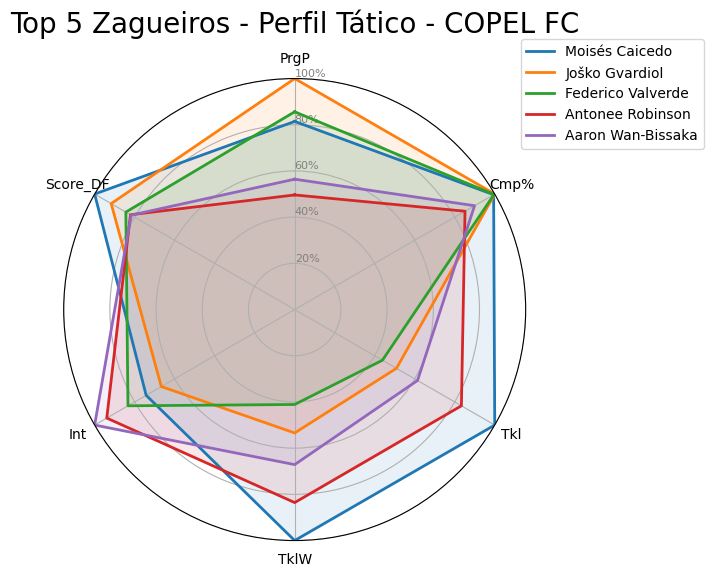

In [14]:
# Função para criar gráfico de radar
def plot_radar_chart(data, title):
    categories = [col for col in data.columns if col != 'Player']
    N = len(categories)

    # Normalizar os dados (0 a 1)
    max_values = data[categories].max()
    normalized_data = data[categories].div(max_values)

    # Configurar o gráfico
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]  # Fechar o círculo

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.set_theta_offset(pi / 2)
    ax.set_theta_direction(-1)

    plt.xticks(angles[:-1], categories)
    ax.set_rlabel_position(0)
    plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["20%", "40%", "60%", "80%", "100%"], color="grey", size=8)
    plt.ylim(0, 1)

    # Plotar para cada jogador
    for i, row in normalized_data.iterrows():
        values = row.tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=data.loc[i, 'Player'])
        ax.fill(angles, values, alpha=0.1)

    plt.title(title, size=20, color='black', y=1.08)
    plt.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1))
    plt.show()

# Gráfico de radar — Top Zagueiros
plot_radar_chart(
    df_top_df[['Player', 'PrgP', 'Cmp%', 'Tkl', 'TklW', 'Int', 'Score_DF']].rename(columns={'Score_DF': 'Score'}),
    title=f'Top {TOP_N} Zagueiros — COPEL FC'
)

### Valor de Mercado dos Top 5 Zagueiros

In [15]:
print("Buscando valores de mercado — Top Zagueiros")
df_top_df_mercado = buscar_mercado_top(df_top_df)
df_top_df_mercado[['Player', 'Squad', 'Age', 'Score_DF', 'Valor_Mercado', 'Data_Contrato', 'Clube_Atual']]

Buscando valores de mercado — Top Zagueiros
  [cache] Moisés Caicedo
  [cache] Joško Gvardiol
  [cache] Federico Valverde
  [cache] Antonee Robinson
  [cache] Aaron Wan-Bissaka


,Player,Squad,Age,Score_DF,Valor_Mercado,Data_Contrato,Clube_Atual
0,Moisés Caicedo,Chelsea,22.0,436.35,€110.00mLast update: 09/12/2025,N/A,Chelsea
1,Joško Gvardiol,Manchester City,22.0,400.30,€70.00mLast update: 09/12/2025,N/A,Man City
2,Federico Valverde,Real Madrid,26.0,368.25,€120.00mLast update: 12/12/2025,N/A,Real Madrid
3,Antonee Robinson,Fulham,26.0,358.20,€25.00mLast update: 09/03/2026,N/A,Fulham
4,Aaron Wan-Bissaka,West Ham,26.0,356.75,€22.00mLast update: 09/12/2025,N/A,West Ham


## 5. Seleção de Volantes (MF)

In [16]:
# Selecionar os TOP_N melhores volantes pelo Score_MF
df_top_mf = (
    df_stats_df_mf[df_stats_df_mf["Pos"].str.contains("MF")]
    .nlargest(TOP_N, "Score_MF")
)
df_top_mf

,Player,Nation,Pos,Squad,Comp,Age,Min,90s,Starts,Cmp,Att,Cmp%,PrgP,1/3,Tkl,TklW,Att 3rd,Int,PPA,KP,PrgC,Att 3rd_stats_possession,Gls,Ast,xG,xAG,Score_DF,Score_MF
Rk,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2061,Pedri,es ESP,MF,Barcelona,es La Liga,21.0,2879,32.0,35,2404,2749,87.4,360,331,61,34,9,26,79,70,92,988,4,5,2.2,7.4,438.7,676.72
1081,Mattéo Guendouzi,fr FRA,MF,Lazio,it Serie A,25.0,3270,36.3,37,1961,2183,89.8,316,287,37,21,5,32,33,43,89,538,1,3,1.4,3.2,387.7,603.04
1508,Manuel Locatelli,it ITA,MF,Juventus,it Serie A,26.0,2822,31.4,34,2134,2431,87.8,294,327,72,49,8,23,31,29,33,408,2,2,1.8,2.5,411.6,593.04
2507,Angelo Stiller,de GER,MF,Stuttgart,de Bundesliga,23.0,2741,30.5,31,2219,2540,87.4,289,271,49,27,6,26,50,59,39,556,1,8,1.8,7.2,367.9,561.82
1091,Bruno Guimarães,br BRA,MF,Newcastle Utd,eng Premier League,26.0,3271,36.3,38,1481,1798,82.4,271,180,83,47,12,29,77,52,64,662,5,6,4.3,6.1,395.5,557.82


In [17]:
#Tabela com os colunas de interesse
df_top_mf = df_top_mf[['Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Min', 'Cmp', 'Cmp%', 'PrgP', 'Tkl', 'TklW', 'Int', 'PrgC','1/3', 'Score_MF']]
df_top_mf

,Player,Nation,Pos,Squad,Comp,Age,Min,Cmp,Cmp%,PrgP,Tkl,TklW,Int,PrgC,1/3,Score_MF
Rk,,,,,,,,,,,,,,,,
2061,Pedri,es ESP,MF,Barcelona,es La Liga,21.0,2879,2404,87.4,360,61,34,26,92,331,676.72
1081,Mattéo Guendouzi,fr FRA,MF,Lazio,it Serie A,25.0,3270,1961,89.8,316,37,21,32,89,287,603.04
1508,Manuel Locatelli,it ITA,MF,Juventus,it Serie A,26.0,2822,2134,87.8,294,72,49,23,33,327,593.04
2507,Angelo Stiller,de GER,MF,Stuttgart,de Bundesliga,23.0,2741,2219,87.4,289,49,27,26,39,271,561.82
1091,Bruno Guimarães,br BRA,MF,Newcastle Utd,eng Premier League,26.0,3271,1481,82.4,271,83,47,29,64,180,557.82


In [18]:
# Gráfico de radar — Top Volantes
plot_radar_chart(
    df_top_mf[['Player', 'PrgP', 'Cmp%', 'TklW', 'Int', 'Score_MF']].rename(columns={'Score_MF': 'Score'}),
    title=f'Top {TOP_N} Volantes — COPEL FC'
)

KeyError: "['Tkl', 'Score_DF'] not in index"

### Valor de Mercado dos Top 5 Volantes

In [ ]:
print("Buscando valores de mercado — Top Volantes")
df_top_mf_mercado = buscar_mercado_top(df_top_mf)
df_top_mf_mercado[['Player', 'Squad', 'Age', 'Score_MF', 'Valor_Mercado', 'Data_Contrato', 'Clube_Atual']]

## 6. Seleção de Atacantes (FW)

In [ ]:
# Filtro para selecionar atacantes
df_filtred_fw = df_filtred[
    df_filtred['Pos'].str.contains(r'^(FW|MF)(,|$)|\b(FW|MF)\b', na=False)
]

# Calcular estatísticas descritivas
kp_stats = df_filtred_fw['KP'].describe()
ppa_stats = df_filtred_fw['PPA'].describe()
xg_stats = df_filtred_fw['xG'].describe()
prgp_stats = df_filtred_fw['PrgP'].describe()

# Filtros mínimos de performance para atacantes
df_stats_fw = df_filtred_fw[
    (df_filtred_fw['PrgP'] > 40) &     # Passes progressivos
    (df_filtred_fw['xG'] >= 1.5) &     # Expected goals
    (df_filtred_fw['KP'] >= 15) &      # Passes chave
    (df_filtred_fw['PPA'] >= 10) &     # Passes para ações de perigo
    (df_filtred_fw['TklW'] >= 15) &    # Tackles vencidos
    (df_filtred_fw['Int'] >= 10)       # Interceptações
].copy()

# ── SCORE ATACANTE (FW) ──────────────────────────────────────
# Foco em criação, finalização e contribuição defensiva
df_stats_fw['Score_FW'] = (
    df_stats_fw['xG'] * 1.5 +     # Expected goals — foco em finalização
    df_stats_fw['KP'] * 1.5 +     # Passes chave
    df_stats_fw['PPA'] * 1.3 +    # Passes para ações de perigo
    df_stats_fw['TklW'] * 0.8 +   # Contribuição defensiva
    df_stats_fw['Int'] * 0.8      # Interceptações
)
df_stats_fw = df_stats_fw.sort_values(by='Score_FW', ascending=False)

# Selecionar os TOP_N melhores atacantes
df_top_fw = df_stats_fw.nlargest(TOP_N, 'Score_FW')
df_top_fw

In [ ]:
#Visualização das métricas descritivas para os zagueiros e volantes
print('métricas Tkl:\n'+ f'{tkl_stats}\n')
print('métricas Tklw:\n'+ f'{tklw_stats}\n')    
print('métricas PrgP:\n'+ f'{prgp}')

In [ ]:
# Gráfico de radar — Top Atacantes
plot_radar_chart(
    df_top_fw[['Player', 'xG', 'PPA', 'KP', 'TklW', 'Int', 'Score_FW']].rename(columns={'Score_FW': 'Score'}),
    title=f'Top {TOP_N} Atacantes — COPEL FC'
)

### Valor de Mercado dos Top 5 Atacantes

In [ ]:
print("Buscando valores de mercado — Top Atacantes")
df_top_fw_mercado = buscar_mercado_top(df_top_fw)
df_top_fw_mercado[['Player', 'Squad', 'Age', 'Score_FW', 'Valor_Mercado', 'Data_Contrato', 'Clube_Atual']]

In [ ]:
#Visualização das métricas descritivas para atacantes
print('métricas KP:\n'+ f'{kp_stats}\n')
print('métricas PPA:\n'+ f'{ppa_stats}\n')    
print('métricas xG:\n'+ f'{xg_stats}\n')
print('métricas PrgP:\n'+ f'{prgp_stats}\n')    

In [ ]:
#df_top_fw.to_csv('top_5_fw.csv', index=False)

## 7. Resumo Comparativo e Exportação

In [ ]:
print("\n" + "="*100)
print("RESUMO EXECUTIVO — TOP TALENTOS PARA COPEL FC")
print("="*100)

print(f"\n{'─'*100}")
print(f"TOP {TOP_N} ZAGUEIROS (Score_DF)")
print(f"{'─'*100}")
cols_df = ['Player', 'Squad', 'Comp', 'Age', 'Score_DF', 'Valor_Mercado', 'Data_Contrato']
cols_df_disp = [c for c in cols_df if c in df_top_df_mercado.columns]
print(df_top_df_mercado[cols_df_disp].to_string(index=False))

print(f"\n{'─'*100}")
print(f"TOP {TOP_N} VOLANTES (Score_MF)")
print(f"{'─'*100}")
cols_mf = ['Player', 'Squad', 'Comp', 'Age', 'Score_MF', 'Valor_Mercado', 'Data_Contrato']
cols_mf_disp = [c for c in cols_mf if c in df_top_mf_mercado.columns]
print(df_top_mf_mercado[cols_mf_disp].to_string(index=False))

print(f"\n{'─'*100}")
print(f"TOP {TOP_N} ATACANTES (Score_FW)")
print(f"{'─'*100}")
cols_fw = ['Player', 'Squad', 'Comp', 'Age', 'Score_FW', 'Valor_Mercado', 'Data_Contrato']
cols_fw_disp = [c for c in cols_fw if c in df_top_fw_mercado.columns]
print(df_top_fw_mercado[cols_fw_disp].to_string(index=False))

print("\n" + "="*100)